# 02a · Seasonal Naive Baseline

**Owner:** Minji · **Reads:** notebook 01 outputs · **Feeds:** notebook 05 (scoring)

The simple baseline every other model has to beat. Each product's forecast comes only from its own sales **before** the window starts. No training, no GPU.

| Run | Forecast for each day |
|---|---|
| `snaive` | Sales on the same weekday last week |
| `smean4` | Average sales on that weekday over the last 4 weeks |

Same 7 windows as 04a/04b. Run on CPU, first with `SAMPLE = True`, then `SAMPLE = False` with T4.

## 0 · Settings

In [7]:
# ---- Mount Drive first so we can find the shared folder ----
import glob
from google.colab import drive
drive.mount("/content/drive")

SAMPLE      = False      # True = 100-product smoke test; False = all ~12,200 California series
RUNS        = ["snaive", "smean4"]   # last week repeated, 4-week weekday average
N_BACKTEST  = 4          # extra 28-day windows before val_1 (same as 04a/04b)
OVERWRITE   = False      # True = redo windows that already have a forecast file

# My shortcut lives inside "DL/ML Group Project", so find it instead of hardcoding
found = glob.glob("/content/drive/MyDrive/*/AML_Term_Project") or glob.glob("/content/drive/MyDrive/AML_Term_Project")
assert found, "Can't find the AML_Term_Project shortcut in My Drive"
DRIVE_DIR   = found[0]
DATA_DIR    = f"{DRIVE_DIR}/data"
OUT_DIR     = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"
print("Using", DATA_DIR)

LOOKBACK    = {"snaive": 7, "smean4": 28}   # days of history each run looks at

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using /content/drive/MyDrive/DL ML Group Project/AML_Term_Project/data


## 1 · Connect

In [8]:
import os, json, time
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2 · Load data and windows

In [9]:
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet",
                     columns=["unique_id", "ds", "y"])
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

# Shared window list (identical to 04a/04b): 4 backtests right before val_1, then val_1, val_2, test.
val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(N_BACKTEST, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

12,196 series, 18,559,286 rows


,start,end
bt_4,2015-11-09,2015-12-06
bt_3,2015-12-07,2016-01-03
bt_2,2016-01-04,2016-01-31
bt_1,2016-02-01,2016-02-28
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


## 3 · Forecast one window
For a window starting on day *S*:
- **History** = only the last 7 (`snaive`) or 28 (`smean4`) days before *S*. The window's actual sales are never used.
- Each of the 28 days gets the value for its weekday: Monday's forecast comes from past Mondays, and so on.
- Products launched on or after *S* have no history, so they're skipped for that window (same rule as 04a/04b).
- A product launched only a few days before *S* may be missing some weekdays. Those days get the product's average over the days it does have.

In [10]:
def forecast_window(run, wname, start, end):
    k = LOOKBACK[run]
    hist = df[df["ds"] < start]
    ids = np.sort(hist["unique_id"].unique())

    recent = hist[hist["ds"] >= start - pd.Timedelta(days=k)].copy()
    recent["dow"] = recent["ds"].dt.dayofweek
    by_dow = recent.groupby(["unique_id", "dow"])["y"].mean().rename("by_dow").reset_index()
    overall = recent.groupby("unique_id")["y"].mean().rename("overall").reset_index()

    days = pd.date_range(start, end, freq="D")
    res = pd.DataFrame({"unique_id": np.repeat(ids, len(days)), "ds": np.tile(days, len(ids))})
    res["dow"] = res["ds"].dt.dayofweek
    res = res.merge(by_dow, on=["unique_id", "dow"], how="left").merge(overall, on="unique_id", how="left")

    n_fallback = int(res["by_dow"].isna().sum())
    if n_fallback:
        print(f"  {wname}: {n_fallback} product-days used the product average (launched < {k} days before)")
    res["forecast"] = res["by_dow"].fillna(res["overall"]).fillna(0).astype("float32")

    res["model"] = run
    res["window"] = wname
    return res[["unique_id", "ds", "model", "window", "forecast"]]

## 4 · Run everything (skips windows already saved)

In [11]:
log_rows = []
for run in RUNS:
    for wname, (start, end) in windows.items():
        path = f"{OUT_DIR}/{run}_{wname}.parquet"
        if os.path.exists(path) and not OVERWRITE:
            print(f"skip  {run:6s} {wname:6s} (already saved)")
            continue
        t0 = time.time()
        res = forecast_window(run, wname, start, end)
        assert len(res) == res["unique_id"].nunique() * H, "every product should have exactly 28 days"
        res.to_parquet(path, index=False)
        secs = time.time() - t0
        n = res["unique_id"].nunique()
        print(f"done  {run:6s} {wname:6s} {n:6,} series  {secs:6.1f}s")
        log_rows.append({"model": run, "window": wname, "series": n, "seconds": round(secs, 1),
                         "device": "cpu", "sample": SAMPLE,
                         "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

  bt_4: 120 product-days used the product average (launched < 7 days before)
done  snaive bt_4   12,175 series     2.2s
done  snaive bt_3   12,177 series     3.3s
done  snaive bt_2   12,185 series     2.7s
  bt_1: 40 product-days used the product average (launched < 7 days before)
done  snaive bt_1   12,190 series     2.3s
done  snaive val_1  12,196 series     2.3s
done  snaive val_2  12,196 series     2.3s
done  snaive test   12,196 series     2.8s
  bt_4: 120 product-days used the product average (launched < 28 days before)
done  smean4 bt_4   12,175 series     3.5s
done  smean4 bt_3   12,177 series     2.3s
done  smean4 bt_2   12,185 series     2.4s
  bt_1: 40 product-days used the product average (launched < 28 days before)
done  smean4 bt_1   12,190 series     2.4s
done  smean4 val_1  12,196 series     2.4s
done  smean4 val_2  12,196 series     4.0s
done  smean4 test   12,196 series     2.6s


,model,window,series,seconds,device,sample,run_at
0,snaive,bt_4,12175,2.2,cpu,False,2026-11-06 18:20
1,snaive,bt_3,12177,3.3,cpu,False,2026-11-06 18:20
2,snaive,bt_2,12185,2.7,cpu,False,2026-11-06 18:20
3,snaive,bt_1,12190,2.3,cpu,False,2026-11-06 18:20
4,snaive,val_1,12196,2.3,cpu,False,2026-11-06 18:20
5,snaive,val_2,12196,2.3,cpu,False,2026-11-06 18:20
6,snaive,test,12196,2.8,cpu,False,2026-11-06 18:20
7,smean4,bt_4,12175,3.5,cpu,False,2026-11-06 18:20
8,smean4,bt_3,12177,2.3,cpu,False,2026-11-06 18:20
9,smean4,bt_2,12185,2.4,cpu,False,2026-11-06 18:20


## 5 · Quick check
Not the official evaluation (that's notebook 05). Mean absolute error per window for:
- our two honest baselines (`snaive`, `smean4`)
- the **"lag-7 of actuals"** check used in 04a/04b, which peeks inside the window from day 8 on (shown only to see how much easier it is)
- Chronos-2 zero-shot, if 04a's files are in the same folder, scored on exactly the same products and days

In [12]:
actual = df[["unique_id", "ds", "y"]]
lag7 = actual.copy()
lag7["ds"] = lag7["ds"] + pd.Timedelta(days=7)
lag7 = lag7.rename(columns={"y": "lag7_actuals"})

rows = []
for wname in windows:
    m = actual
    for run in RUNS:
        f = pd.read_parquet(f"{OUT_DIR}/{run}_{wname}.parquet")[["unique_id", "ds", "forecast"]]
        m = m.merge(f.rename(columns={"forecast": run}), on=["unique_id", "ds"])
    m = m.merge(lag7, on=["unique_id", "ds"], how="left")
    m["lag7_actuals"] = m["lag7_actuals"].fillna(0)
    cpath = f"{OUT_DIR}/chronos2_zs_{wname}.parquet"
    if os.path.exists(cpath):
        c = pd.read_parquet(cpath)[["unique_id", "ds", "forecast"]].rename(columns={"forecast": "chronos2_zs"})
        m = m.merge(c, on=["unique_id", "ds"])   # same products and days for every column
    row = {"window": wname, "series": m["unique_id"].nunique()}
    for col in RUNS + ["lag7_actuals", "chronos2_zs"]:
        if col in m:
            row[f"MAE {col}"] = (m[col] - m["y"]).abs().mean()
    rows.append(row)

check = pd.DataFrame(rows).set_index("window")
if "MAE chronos2_zs" in check:
    check["Chronos-2 vs snaive"] = (1 - check["MAE chronos2_zs"] / check["MAE snaive"]).map("{:.0%}".format)
    check["Chronos-2 vs lag-7 of actuals"] = (1 - check["MAE chronos2_zs"] / check["MAE lag7_actuals"]).map("{:.0%}".format)
check.round(3)

,series,MAE snaive,MAE smean4,MAE lag7_actuals,MAE chronos2_zs,Chronos-2 vs snaive,Chronos-2 vs lag-7 of actuals
window,,,,,,,
bt_4,12175,1.249,1.110,1.206,0.920,26%,24%
bt_3,12177,1.268,1.090,1.210,0.911,28%,25%
bt_2,12185,1.277,1.118,1.218,0.938,26%,23%
bt_1,12190,1.268,1.107,1.250,0.968,24%,23%
val_1,12196,1.294,1.135,1.275,0.986,24%,23%
val_2,12196,1.324,1.139,1.291,0.995,25%,23%
test,12196,1.335,1.172,1.325,1.026,23%,23%


## 6 · Look at a few products
Actual sales (black) vs. the two baselines on the **test** window, for one slow, one medium and one fast seller.

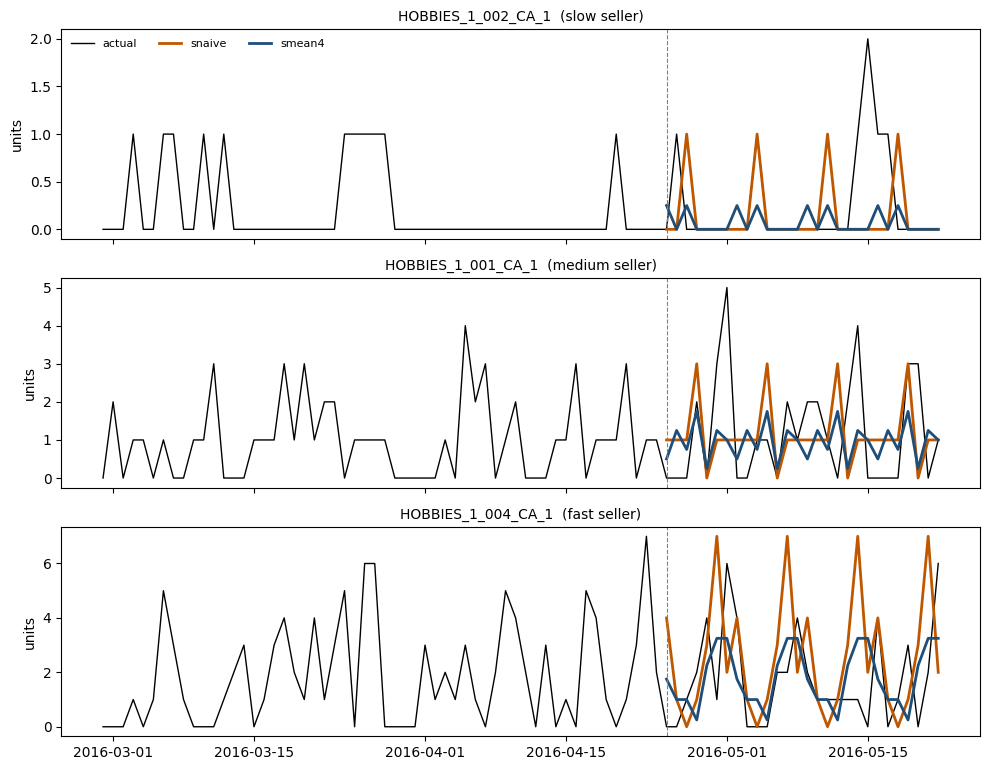

In [13]:
import matplotlib.pyplot as plt
start, end = windows["test"]
fc = {run: pd.read_parquet(f"{OUT_DIR}/{run}_test.parquet") for run in RUNS}
static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
pick = (static[static["unique_id"].isin(fc[RUNS[0]]["unique_id"])]
        .groupby("sales_speed", observed=True)["unique_id"].first())

colors = {"snaive": "#BF5700", "smean4": "#1f4e79"}
fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.6 * len(pick)), sharex=True)
for ax, (speed, uid) in zip(np.atleast_1d(axes), pick.items()):
    hist = df[(df["unique_id"] == uid) & (df["ds"] >= start - pd.Timedelta(days=56)) & (df["ds"] <= end)]
    ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="actual")
    for run, f in fc.items():
        one = f[f["unique_id"] == uid]
        ax.plot(one["ds"], one["forecast"], color=colors.get(run), lw=2, label=run)
    ax.axvline(start, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{uid}  ({speed} seller)", fontsize=10); ax.set_ylabel("units")
np.atleast_1d(axes)[0].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
if not SAMPLE:
    plt.savefig(f"{DATA_DIR}/figures/11_seasonal_naive_examples.png", dpi=150, bbox_inches="tight")
plt.show()